In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
df.shape

(20640, 10)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


### Analizamos que tienen en comun las filas que tienen `total_bedrooms` en `nulos`.

In [8]:
df_nulos = df[df['total_bedrooms'].isnull()]
df_nulos

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
290,-122.16,37.77,47.0,1256.0,NaN,570.0,218.0,4.3750,161900.0,NEAR BAY
341,-122.17,37.75,38.0,992.0,NaN,732.0,259.0,1.6196,85100.0,NEAR BAY
538,-122.28,37.78,29.0,5154.0,NaN,3741.0,1273.0,2.5762,173400.0,NEAR BAY
563,-122.24,37.75,45.0,891.0,NaN,384.0,146.0,4.9489,247100.0,NEAR BAY
696,-122.10,37.69,41.0,746.0,NaN,387.0,161.0,3.9063,178400.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20267,-119.19,34.20,18.0,3620.0,NaN,3171.0,779.0,3.3409,220500.0,NEAR OCEAN
20268,-119.18,34.19,19.0,2393.0,NaN,1938.0,762.0,1.6953,167400.0,NEAR OCEAN
20372,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,410700.0,<1H OCEAN
20460,-118.75,34.29,17.0,5512.0,NaN,2734.0,814.0,6.6073,258100.0,<1H OCEAN


In [9]:
df_nulos['ocean_proximity'].value_counts(normalize=True)

ocean_proximity
<1H OCEAN     0.492754
INLAND        0.265700
NEAR OCEAN    0.144928
NEAR BAY      0.096618
Name: proportion, dtype: float64

In [10]:
df['ocean_proximity'].value_counts(normalize=True)

ocean_proximity
<1H OCEAN     0.442636
INLAND        0.317393
NEAR OCEAN    0.128779
NEAR BAY      0.110950
ISLAND        0.000242
Name: proportion, dtype: float64

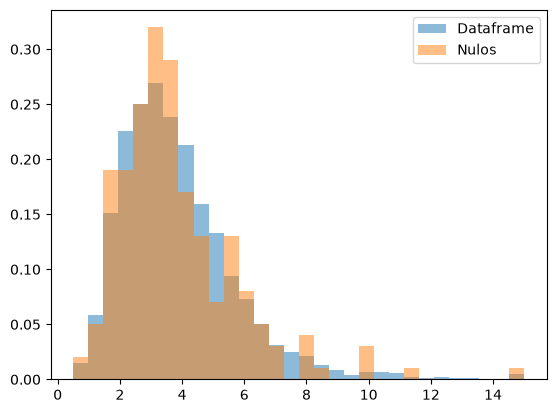

In [11]:
bordes = np.histogram_bin_edges(df['median_income'],bins=30)
plt.hist(df['median_income'],
        bins=bordes,
        density=True,
        alpha=0.5,
        label= "Dataframe")

plt.hist(df_nulos['median_income'],
         bins=bordes,
         density=True,
         alpha=0.5,
         label="Nulos")

plt.legend()
plt.show()

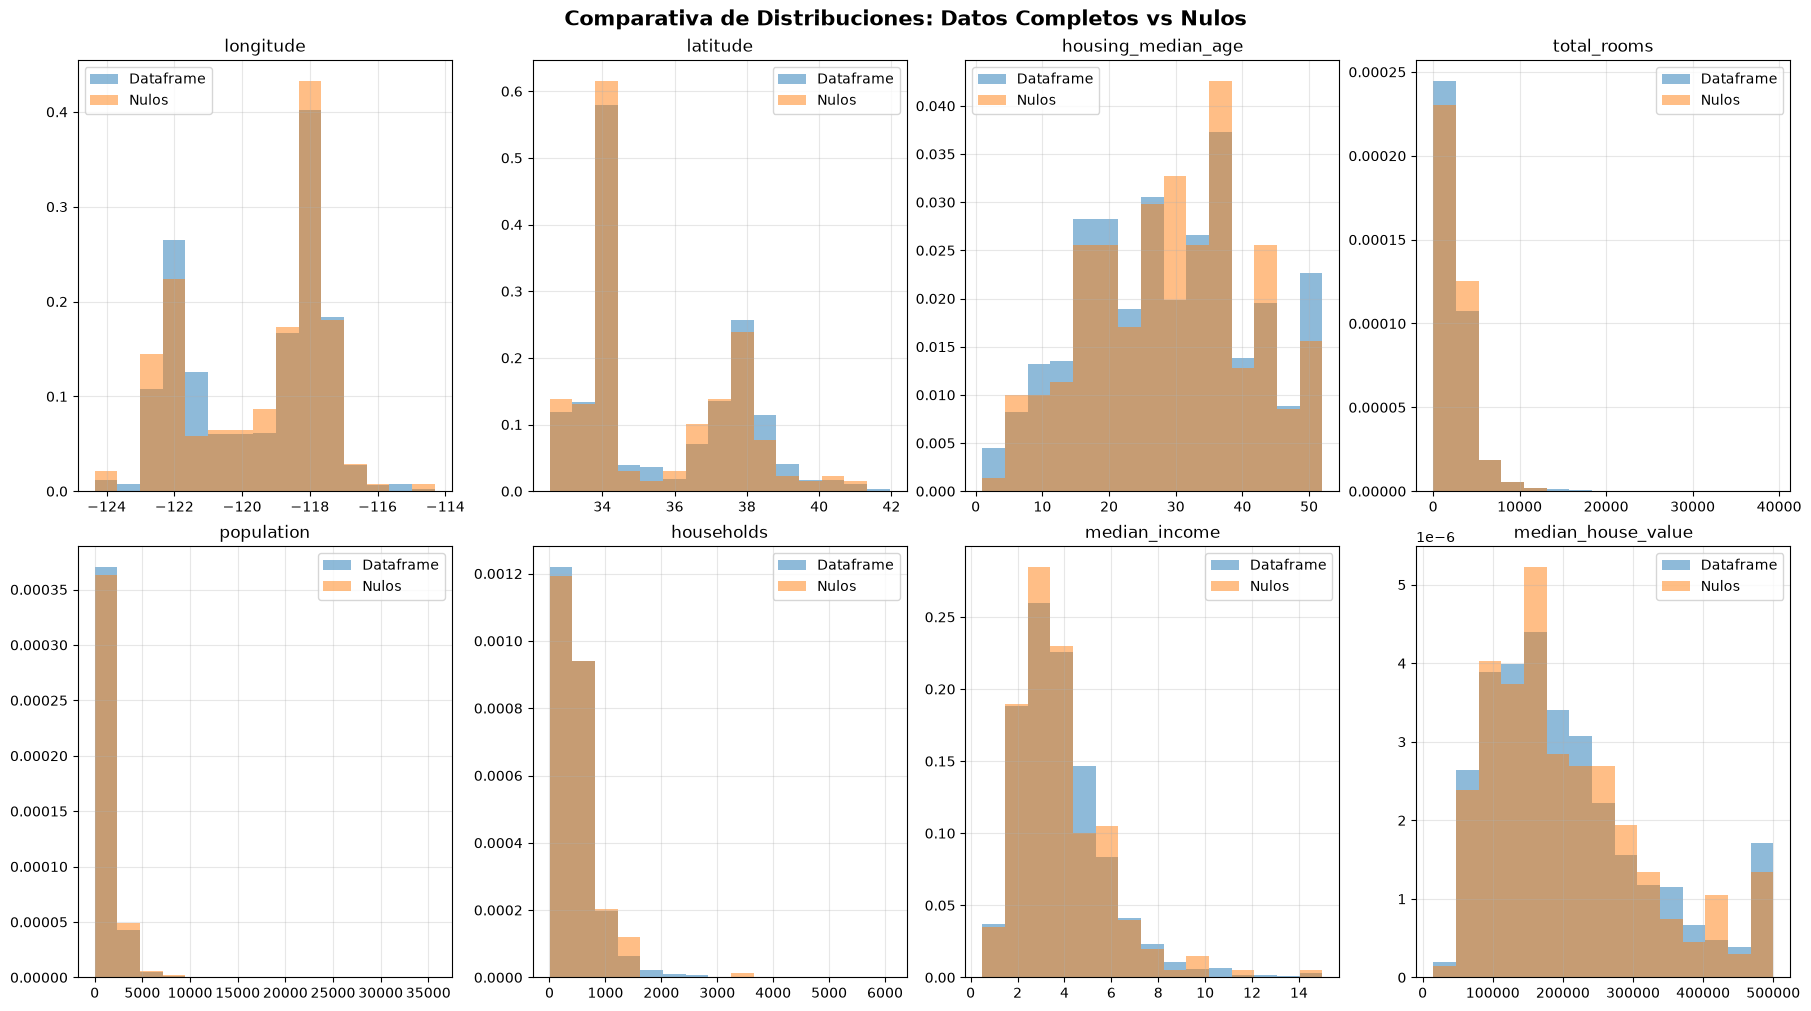

In [12]:
columnas = ['longitude','latitude','housing_median_age','total_rooms',
            'population','households', 'median_income' ,'median_house_value']


# fig, axs = plt.subplots(2, 4, figsize=(18, 10), layout='constrained')
# axs_planos = axs.flatten()  # Convierte la matriz en una lista simple de 8 espacios

# for i, col in enumerate(columnas):
#     ax = axs_planos[i]
    
#     ax.hist(df[col], density=True, alpha=0.5, label='Completos')
#     ax.hist(df_nulos[col], density=True, alpha=0.5, label='Nulos')
#     ax.set_title(col)


fig, axs = plt.subplots(2,4, figsize=(18,10), layout='constrained')

for i, col in enumerate(columnas):
        fila = i//4
        columna = i%4

        ax = axs[fila,columna]

        bordes = np.histogram_bin_edges(df[col],bins=15)

        ax.hist(df[col],
                bins=bordes,
                density=True,
                alpha=0.5,
                label= "Dataframe")

        ax.hist(df_nulos[col],
                bins=bordes,
                density=True,
                alpha=0.5,
                label="Nulos")

        ax.set_title(col, fontsize=12)
        ax.legend()
        ax.grid(True, alpha=0.3)

fig.suptitle("Comparativa de Distribuciones: Datos Completos vs Nulos", fontsize=15, weight='bold')
plt.show()

La evidencia **muestra** que los nulos de `total_bedrooms` no se concentran en ninguna zona ni tipo de zona que podamos detectar con estas variables. Eso no prueba que sean “al azar”, pero sí que no hay un sesgo visible. Al alrededor del 1% de las filas del dataset, en este caso se decide eliminar las filas con `total_bedrooms` nulos.

In [13]:
df_limpio = df.dropna(subset=['total_bedrooms'])

In [14]:
df_limpio.shape

(20433, 10)

In [15]:
df_limpio.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [16]:
df_limpio.duplicated().sum()

np.int64(0)

#### No se encontraron filas duplicadas.

In [17]:
df_limpio.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000
mean,-119.570689,35.633221,28.633094,2636.504233,537.870553,1424.946949,499.433465,3.871162,206864.413155
std,2.003578,2.136348,12.591805,2185.269567,421.385070,1133.208490,382.299226,1.899291,115435.667099
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1450.000000,296.000000,787.000000,280.000000,2.563700,119500.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.536500,179700.000000
75%,-118.010000,37.720000,37.000000,3143.000000,647.000000,1722.000000,604.000000,4.744000,264700.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [18]:
calculo = (df_limpio["median_house_value"] == 500001).sum()
calculo

np.int64(958)

In [19]:
(calculo / df_limpio.shape[0])*100

np.float64(4.6884941026770415)

### ~4.7% de zonas que son afectadas por tope de media de precio.

In [20]:
df_tope_value = df_limpio[df_limpio['median_house_value'] == 500001]

print(df_tope_value['ocean_proximity'].value_counts(normalize=True))
df_limpio['ocean_proximity'].value_counts(normalize=True)

ocean_proximity
<1H OCEAN     0.552192
NEAR OCEAN    0.218163
NEAR BAY      0.201461
INLAND        0.028184
Name: proportion, dtype: float64


ocean_proximity
<1H OCEAN     0.442128
INLAND        0.317917
NEAR OCEAN    0.128615
NEAR BAY      0.111095
ISLAND        0.000245
Name: proportion, dtype: float64

958 zonas (4,7%) figuran con median_house_value = 500.001, que parece ser un tope del dataset.  
Esas zonas se concentran cerca del mar (solo 2,8% son INLAND, contra 31,8% en el total).  
Por el tope, entre estas zonas no se puede saber cuáles son más caras que otras.  

In [21]:
df_sin_tope = df_limpio[df_limpio['median_house_value'] != 500001]
df_sin_tope.shape

(19475, 10)

In [22]:
print(f'df_limpio {df_limpio["median_house_value"].mean()}')
print(f'df_sin_tope {df_sin_tope["median_house_value"].mean()}')

df_limpio 206864.41315519012
df_sin_tope 192444.6519127086


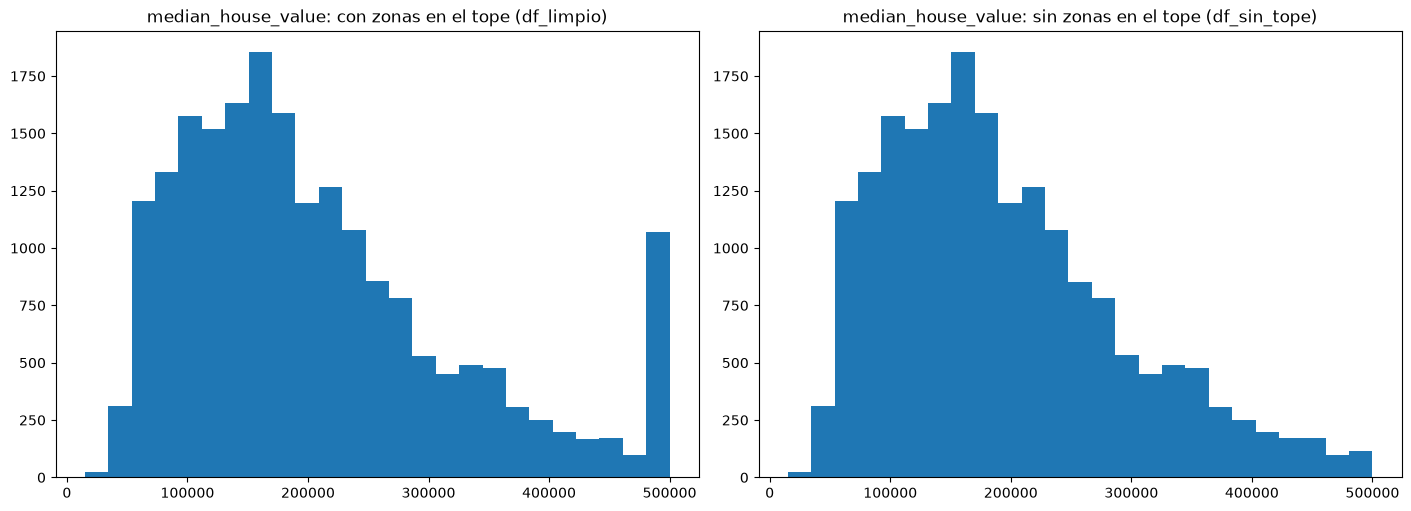

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')

axs[0].hist(df_limpio['median_house_value'], bins=25)
axs[0].set_title('median_house_value: con zonas en el tope (df_limpio)')

axs[1].hist(df_sin_tope['median_house_value'], bins=25)
axs[1].set_title('median_house_value: sin zonas en el tope (df_sin_tope)')

plt.show()

In [24]:
conteo = df_limpio['ocean_proximity'].value_counts()
conteo

ocean_proximity
<1H OCEAN     9034
INLAND        6496
NEAR OCEAN    2628
NEAR BAY      2270
ISLAND           5
Name: count, dtype: int64

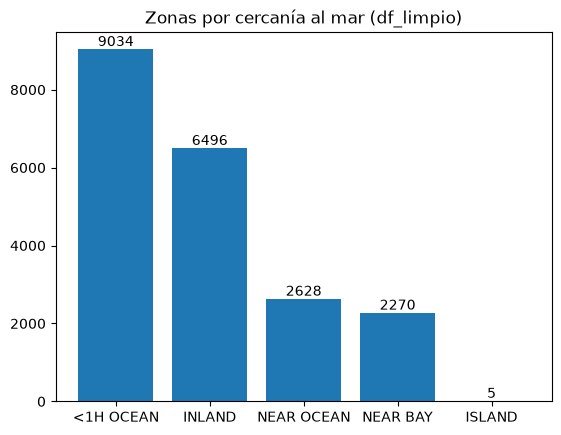

In [25]:
barras = plt.bar(conteo.index, conteo.values)
plt.bar_label(barras)
plt.title('Zonas por cercanía al mar (df_limpio)')
plt.show()

In [26]:
print("df limpio ",df_limpio.groupby('ocean_proximity')['median_house_value'].mean())
print("df sin tope ",df_sin_tope.groupby('ocean_proximity')['median_house_value'].mean())

df limpio  ocean_proximity
<1H OCEAN     240267.990812
INLAND        124896.863147
ISLAND        380440.000000
NEAR BAY      259279.292070
NEAR OCEAN    249042.355023
Name: median_house_value, dtype: float64
df sin tope  ocean_proximity
<1H OCEAN     224112.933568
INLAND        123331.271603
ISLAND        380440.000000
NEAR BAY      236910.832932
NEAR OCEAN    227359.694088
Name: median_house_value, dtype: float64


In [27]:
df_tope_value['ocean_proximity'].value_counts() / df_limpio['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     0.058557
INLAND        0.004156
ISLAND             NaN
NEAR BAY      0.085022
NEAR OCEAN    0.079528
Name: count, dtype: float64

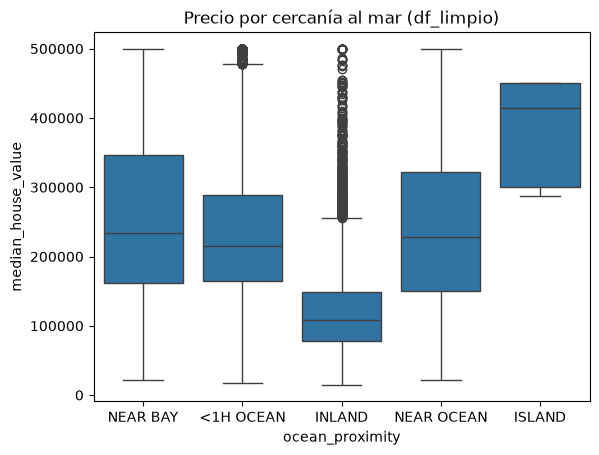

In [28]:
sns.boxplot(data=df_limpio, x='ocean_proximity', y='median_house_value')
plt.title('Precio por cercanía al mar (df_limpio)')
plt.show()

In [29]:
inland = df_limpio[df_limpio['ocean_proximity'] == 'INLAND']
(inland['median_house_value'] > 255000).sum()

np.int64(333)

In [30]:
(inland['median_house_value'] == 500001).sum()

np.int64(27)

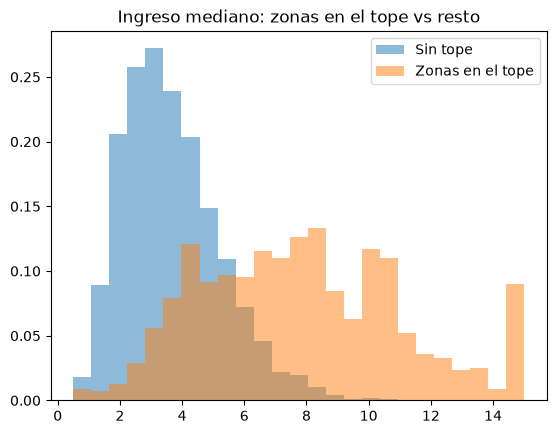

In [31]:
bordes = np.histogram_bin_edges(df_limpio['median_income'], bins=25)

plt.hist(df_sin_tope['median_income'], bins=bordes, density=True, alpha=0.5, label='Sin tope')
plt.hist(df_tope_value['median_income'], bins=bordes, density=True, alpha=0.5, label='Zonas en el tope')
plt.title('Ingreso mediano: zonas en el tope vs resto')
plt.legend()
plt.show()

In [ ]:
(df_tope_value['median_income'] >= 15).sum()

np.int64(47)

In [ ]:
df_ingreso_tope = df_limpio[df_limpio['median_income'] >= 15]

print(len(df_ingreso_tope))
(df_ingreso_tope['median_house_value'] == 500001).sum()

50


np.int64(47)

# Analisis complejo

In [ ]:
df_limpio.corr(numeric_only=True)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924616,-0.109357,0.045480,0.069608,0.100270,0.056513,-0.015550,-0.045398
latitude,-0.924616,1.000000,0.011899,-0.036667,-0.066983,-0.108997,-0.071774,-0.079626,-0.144638
housing_median_age,-0.109357,0.011899,1.000000,-0.360628,-0.320451,-0.295787,-0.302768,-0.118278,0.106432
total_rooms,0.045480,-0.036667,-0.360628,1.000000,0.930380,0.857281,0.918992,0.197882,0.133294
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.100270,-0.108997,-0.295787,0.857281,0.877747,1.000000,0.907186,0.005087,-0.025300
households,0.056513,-0.071774,-0.302768,0.918992,0.979728,0.907186,1.000000,0.013434,0.064894
median_income,-0.015550,-0.079626,-0.118278,0.197882,-0.007723,0.005087,0.013434,1.000000,0.688355
median_house_value,-0.045398,-0.144638,0.106432,0.133294,0.049686,-0.025300,0.064894,0.688355,1.000000


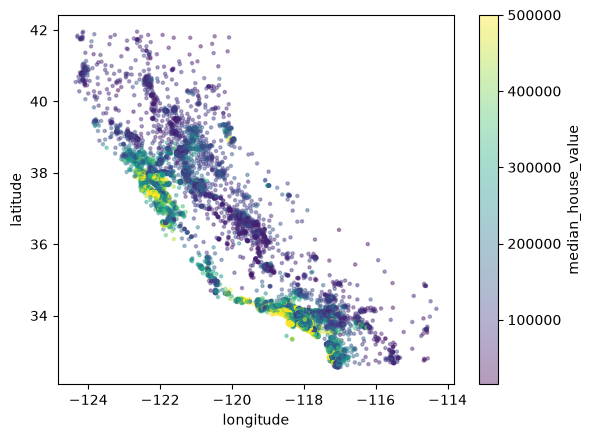

In [35]:
plt.scatter(df_limpio['longitude'], df_limpio['latitude'],
            c=df_limpio['median_house_value'], s=5, alpha=0.4)
plt.colorbar(label='median_house_value')
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.show()

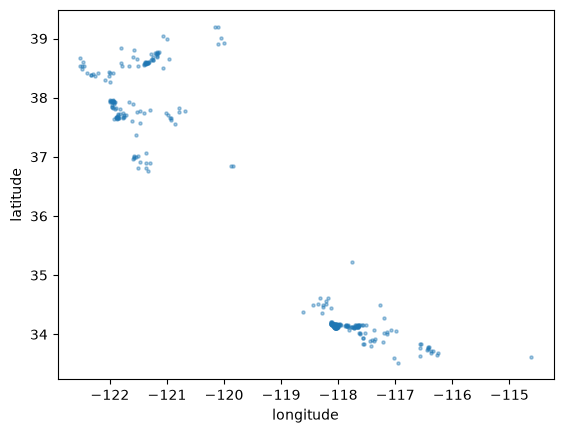

In [49]:
inland_caras = inland[inland['median_house_value'] > 255000]

plt.scatter(inland_caras['longitude'], inland_caras['latitude'], s=5, alpha=0.4)
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.show()

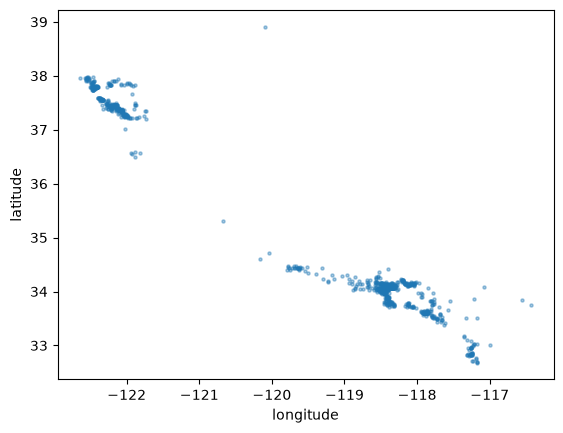

In [48]:
plt.scatter(df_tope_value['longitude'], df_tope_value['latitude'], s=5, alpha=0.4)
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.show()

Los datos sugieren que la cercanía a ciudades grandes, combinada con la costa, está detrás de las zonas más caras; el dataset no permite medir cada efecto por separado

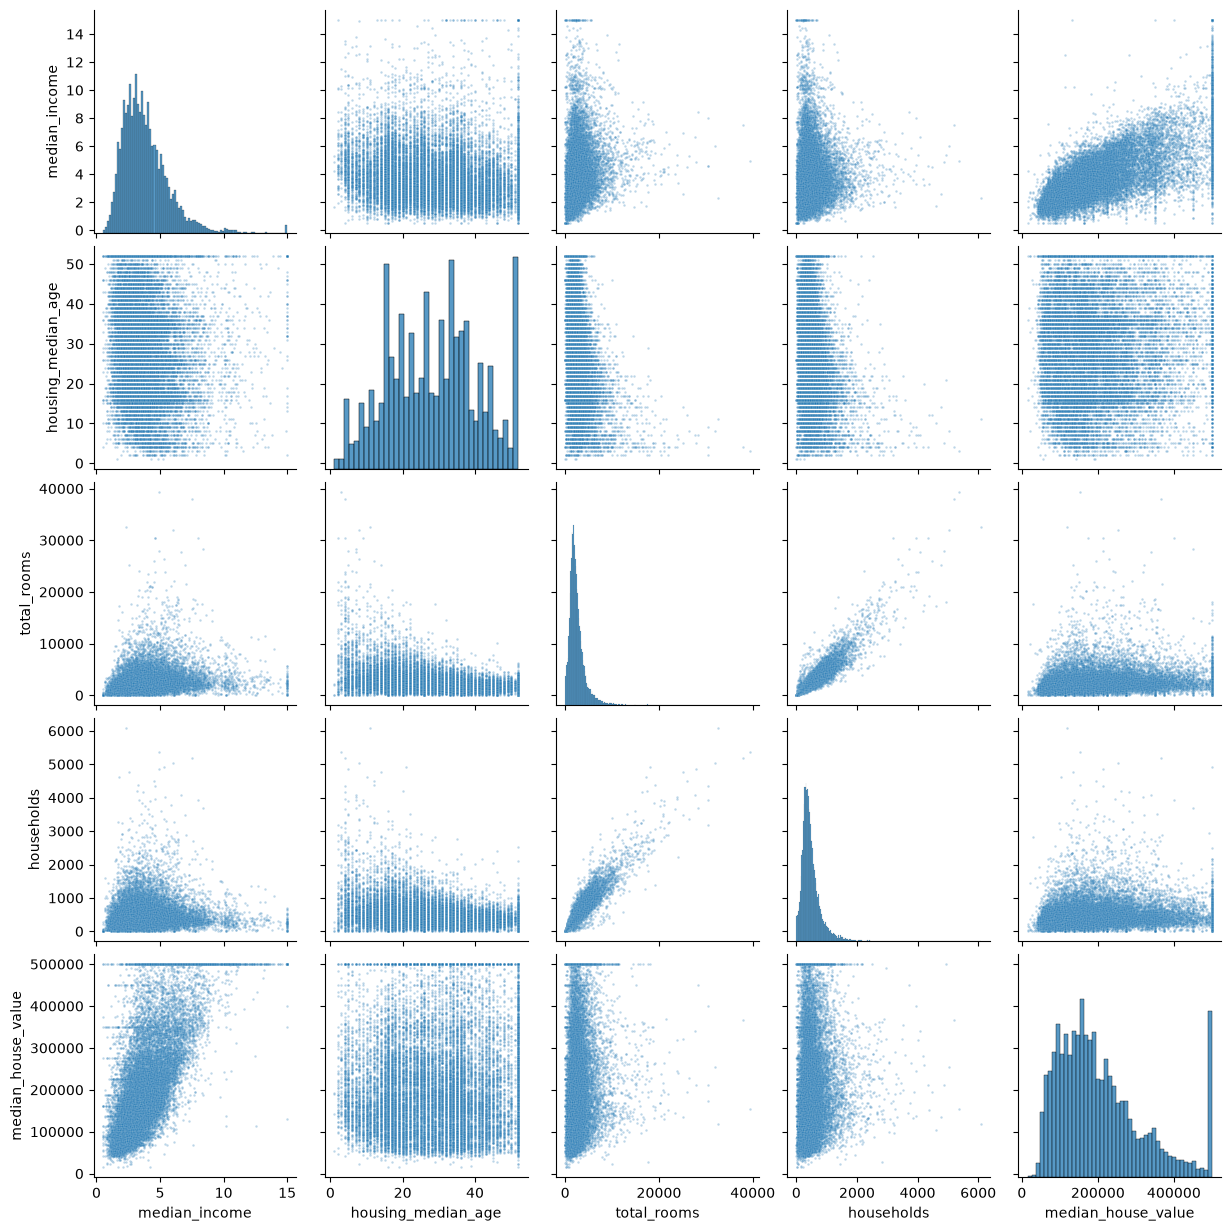

In [50]:
columnas_pair = ['median_income', 'housing_median_age', 'total_rooms',
                 'households', 'median_house_value']

sns.pairplot(df_limpio[columnas_pair], plot_kws={'s': 3, 'alpha': 0.3})
plt.show()

In [51]:
(df_limpio['housing_median_age'] == 52).sum()

np.int64(1265)

In [52]:
df_limpio['housing_median_age'].value_counts().head()

housing_median_age
52.0    1265
36.0     856
35.0     818
16.0     762
17.0     694
Name: count, dtype: int64

Aparentemente hay un tope en `housing_median_age` de 52.

## mapa de calor

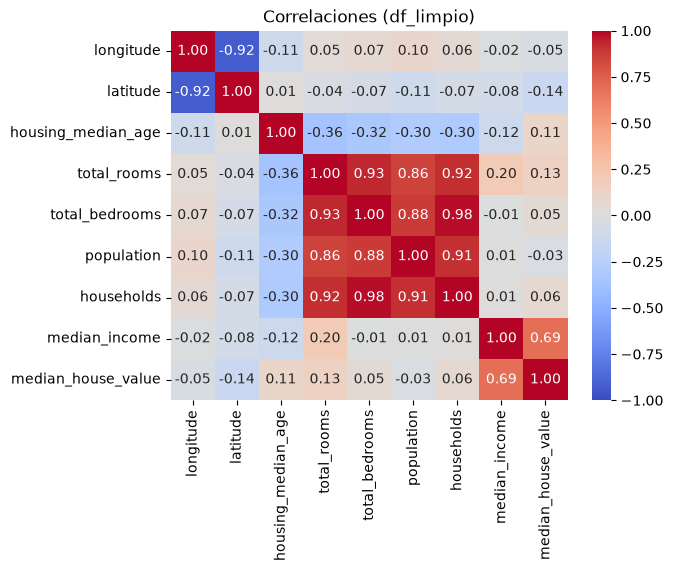

In [53]:
matriz = df_limpio.corr(numeric_only=True)

sns.heatmap(matriz, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlaciones (df_limpio)')
plt.show()

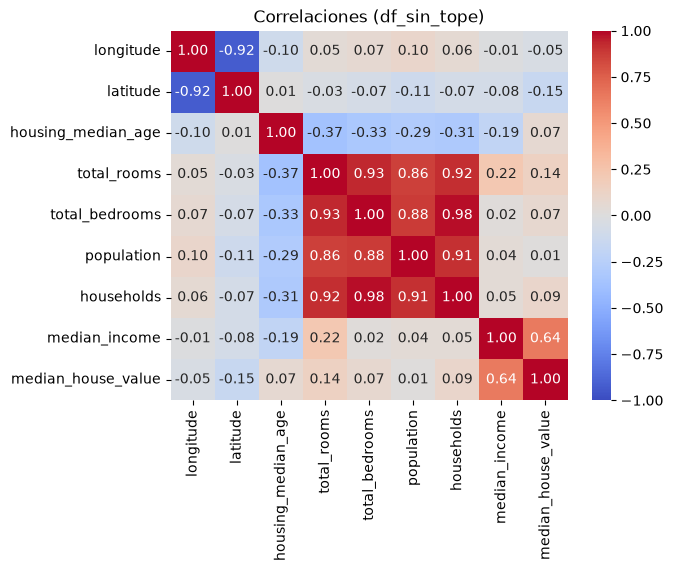

In [54]:
matriz_sin_tope = df_sin_tope.corr(numeric_only=True)

sns.heatmap(matriz_sin_tope, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlaciones (df_sin_tope)')
plt.show()